**Task 1 – Cellular Coverage Design**

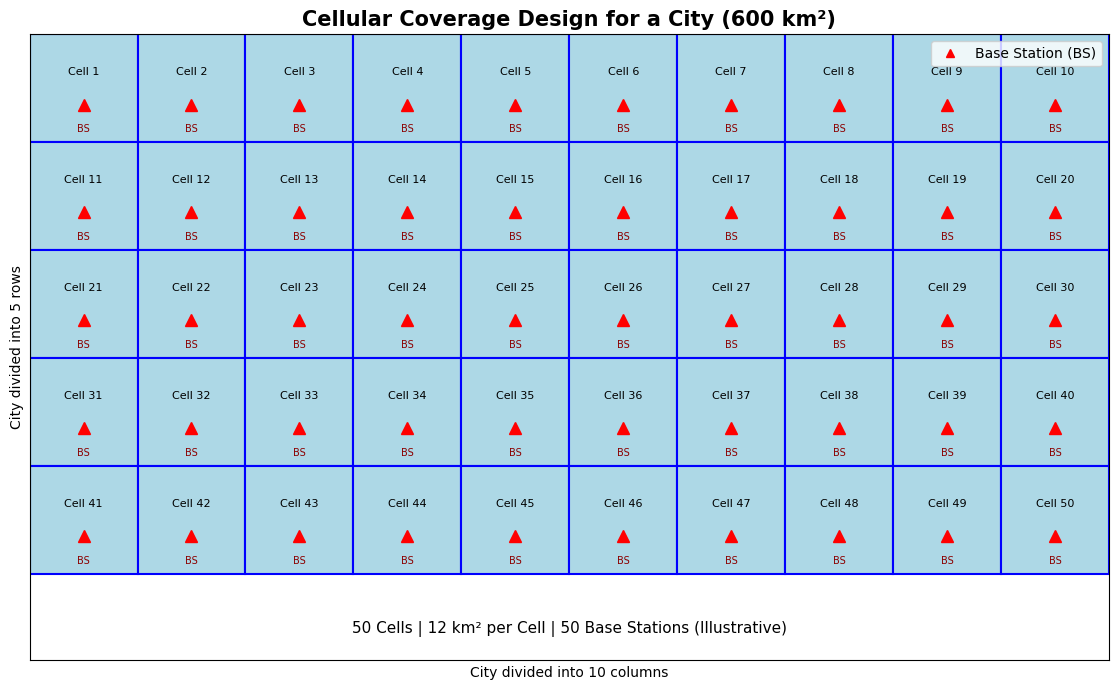

In [1]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

rows = 5
cols = 10
total_area = 600
cell_area = 12

fig, ax = plt.subplots(figsize=(14, 7))

for row in range(rows):
    for col in range(cols):
        x = col
        y = rows - row - 1

        cell = patches.Rectangle(
            (x, y), 1, 1,
            linewidth=1.5,
            edgecolor="blue",
            facecolor="lightblue"
        )
        ax.add_patch(cell)

        cell_no = row * cols + col + 1
        ax.text(
            x + 0.5, y + 0.65,
            f"Cell {cell_no}",
            ha="center", va="center",
            fontsize=8
        )

        ax.plot(
            x + 0.5, y + 0.35,
            marker="^",
            color="red",
            markersize=8
        )
        ax.text(
            x + 0.5, y + 0.12,
            "BS",
            ha="center", va="center",
            fontsize=7,
            color="darkred"
        )

ax.set_title(
    "Cellular Coverage Design for a City (600 km²)",
    fontsize=15,
    fontweight="bold"
)
ax.text(
    cols / 2, -0.55,
    "50 Cells | 12 km² per Cell | 50 Base Stations (Illustrative)",
    ha="center", fontsize=11
)

ax.set_xlim(0, cols)
ax.set_ylim(-0.8, rows)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("City divided into 10 columns")
ax.set_ylabel("City divided into 5 rows")

# Legend
ax.plot([], [], "^", color="red", label="Base Station (BS)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


**Task 2 – Frequency Reuse Optimization**



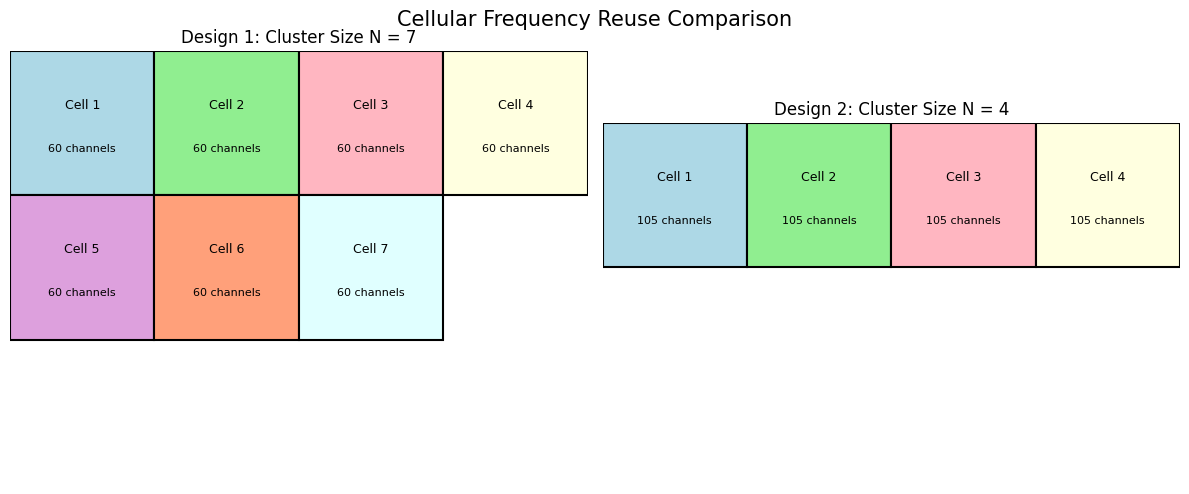

In [2]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_cluster(ax, cluster_size, total_channels):
    colors = [
        "lightblue", "lightgreen", "lightpink",
        "lightyellow", "plum", "lightsalmon",
        "lightcyan"
    ]

    for i in range(cluster_size):
        row = i // 4
        col = i % 4

        cell = patches.Rectangle(
            (col, -row), 1, 1,
            facecolor=colors[i % len(colors)],
            edgecolor="black",
            linewidth=1.5
        )
        ax.add_patch(cell)

        channels = total_channels // cluster_size

        ax.text(
            col + 0.5, -row + 0.6,
            f"Cell {i + 1}",
            ha="center", fontsize=9
        )
        ax.text(
            col + 0.5, -row + 0.3,
            f"{channels} channels",
            ha="center", fontsize=8
        )

    rows = (cluster_size + 3) // 4
    ax.set_xlim(0, 4)
    ax.set_ylim(-rows, 1)
    ax.set_aspect("equal")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

draw_cluster(axes[0], 7, 420)
axes[0].set_title("Design 1: Cluster Size N = 7")

draw_cluster(axes[1], 4, 420)
axes[1].set_title("Design 2: Cluster Size N = 4")

fig.suptitle("Cellular Frequency Reuse Comparison", fontsize=15)
plt.tight_layout()
plt.show()


**Task 3 – Interference Management**

In [3]:

import math

desired_signal = -65
interference_1 = -80
interference_2 = -83

I1 = 10 ** (interference_1 / 10)
I2 = 10 ** (interference_2 / 10)

total_interference = I1 + I2

total_interference_dbm = 10 * math.log10(total_interference)

ci_initial = desired_signal - total_interference_dbm

ci_improved = ci_initial + 5

print("Interference 1:", I1, "mW")
print("Interference 2:", I2, "mW")
print("Total interference:", total_interference, "mW")
print("Total interference:", total_interference_dbm, "dBm")
print("Initial C/I ratio:", ci_initial, "dB")
print("Improved C/I ratio:", ci_improved, "dB")


Interference 1: 1e-08 mW
Interference 2: 5.011872336272715e-09 mW
Total interference: 1.5011872336272717e-08 mW
Total interference: -78.23565137563514 dBm
Initial C/I ratio: 13.235651375635143 dB
Improved C/I ratio: 18.235651375635143 dB


**Task 4 – Access Channel Congestion**

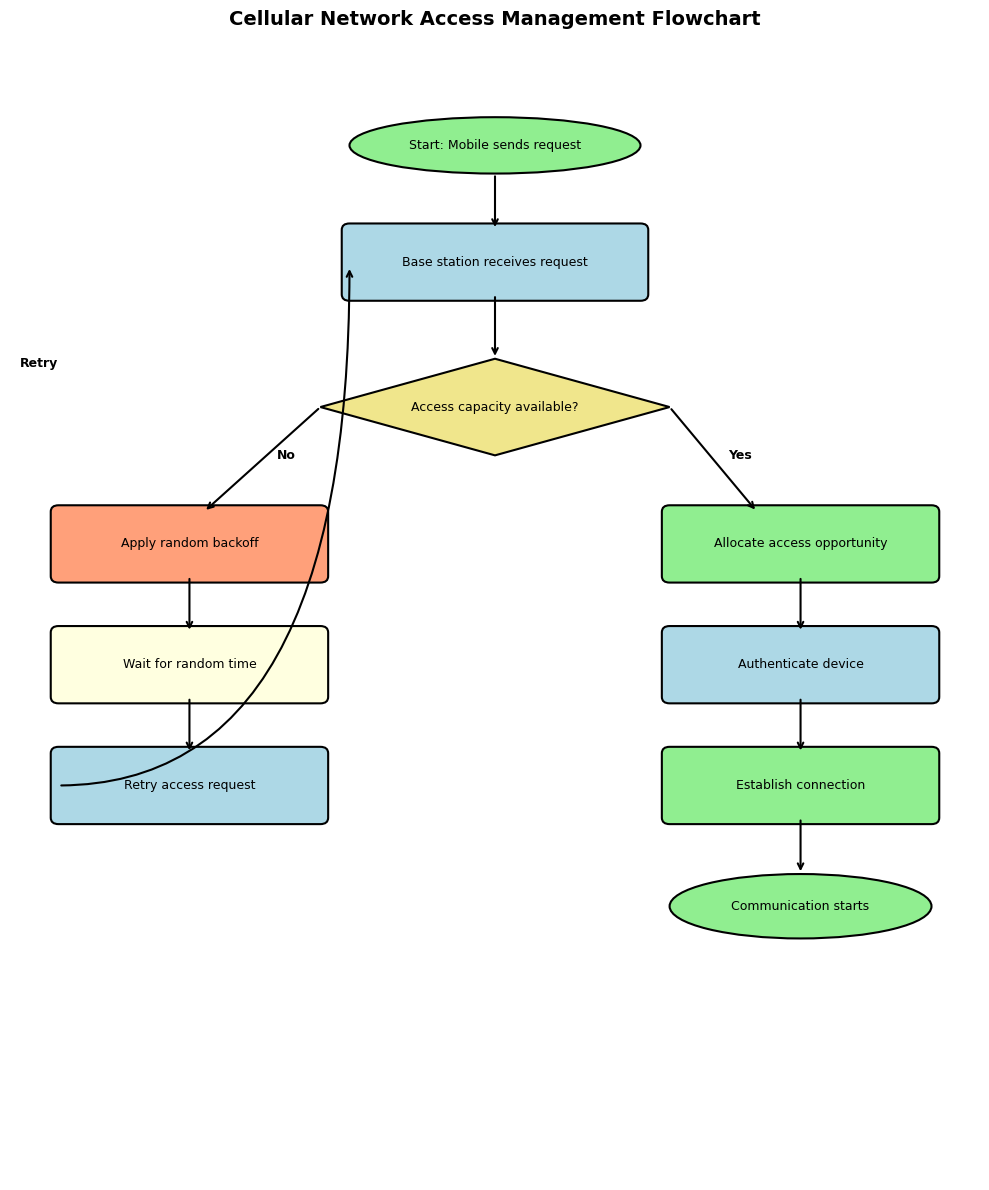

In [5]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

def draw_box(x, y, w, h, text, color="lightblue",
             shape="box"):
    if shape == "diamond":
        points = [
            (x + w/2, y + h),
            (x + w, y + h/2),
            (x + w/2, y),
            (x, y + h/2)
        ]
        patch = Polygon(
            points, closed=True,
            facecolor=color, edgecolor="black", linewidth=1.5
        )
    elif shape == "oval":
        patch = plt.matplotlib.patches.Ellipse(
            (x + w/2, y + h/2), w, h,
            facecolor=color, edgecolor="black", linewidth=1.5
        )
    else:
        patch = FancyBboxPatch(
            (x, y), w, h,
            boxstyle="round,pad=0.08",
            facecolor=color, edgecolor="black",
            linewidth=1.5
        )

    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center", fontsize=9,
            wrap=True)

def arrow(x1, y1, x2, y2, label=""):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )
    if label:
        ax.text((x1+x2)/2 + 0.15, (y1+y2)/2,
                label, fontsize=9, fontweight="bold")

draw_box(3.5, 12.5, 3, 0.7,
         "Start: Mobile sends request", "lightgreen", "oval")
draw_box(3.5, 11, 3, 0.8,
         "Base station receives request")
draw_box(3.2, 9, 3.6, 1.2,
         "Access capacity available?", "khaki", "diamond")

arrow(5, 12.5, 5, 11.8)
arrow(5, 11, 5, 10.2)

draw_box(6.8, 7.5, 2.7, 0.8,
         "Allocate access opportunity", "lightgreen")
draw_box(6.8, 6, 2.7, 0.8,
         "Authenticate device", "lightblue")
draw_box(6.8, 4.5, 2.7, 0.8,
         "Establish connection", "lightgreen")
draw_box(6.8, 3, 2.7, 0.8,
         "Communication starts", "lightgreen", "oval")

arrow(6.8, 9.6, 7.7, 8.3, "Yes")
arrow(8.15, 7.5, 8.15, 6.8)
arrow(8.15, 6, 8.15, 5.3)
arrow(8.15, 4.5, 8.15, 3.8)

draw_box(0.5, 7.5, 2.7, 0.8,
         "Apply random backoff", "lightsalmon")
draw_box(0.5, 6, 2.7, 0.8,
         "Wait for random time", "lightyellow")
draw_box(0.5, 4.5, 2.7, 0.8,
         "Retry access request", "lightblue")

arrow(3.2, 9.6, 2, 8.3, "No")
arrow(1.85, 7.5, 1.85, 6.8)
arrow(1.85, 6, 1.85, 5.3)

ax.annotate(
    "", xy=(3.5, 11.35), xytext=(0.5, 4.9),
    arrowprops=dict(
        arrowstyle="->", lw=1.5,
        connectionstyle="angle3,angleA=0,angleB=90"
    )
)
ax.text(0.1, 10.1, "Retry", fontsize=9, fontweight="bold")

ax.set_title(
    "Cellular Network Access Management Flowchart",
    fontsize=14, fontweight="bold", pad=20
)

plt.tight_layout()
plt.show()


**Task 5 – Mobile Network Architecture**

Total subscribers: 5000
Simultaneous call attempts: 400
BSS transactions required: 400
SSS transactions required: 400
Minimum BSS capacity: 100 transactions/second
Minimum SSS capacity: 100 transactions/second


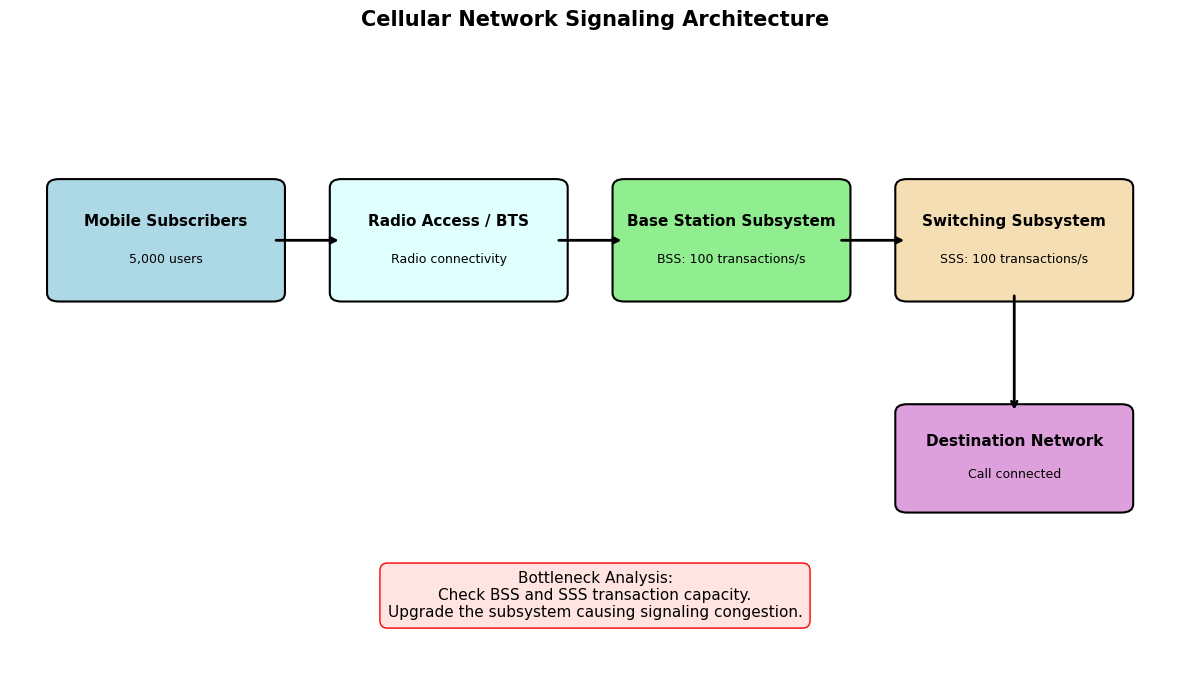

In [6]:
subscribers = 5000
simultaneous_percentage = 8
time_limit = 4
call_attempts = subscribers * simultaneous_percentage / 100
bss_transactions = call_attempts
sss_transactions = call_attempts

bss_rate = bss_transactions / time_limit
sss_rate = sss_transactions / time_limit

print("Total subscribers:", subscribers)
print("Simultaneous call attempts:", int(call_attempts))
print("BSS transactions required:", int(bss_transactions))
print("SSS transactions required:", int(sss_transactions))
print("Minimum BSS capacity:", int(bss_rate),
      "transactions/second")
print("Minimum SSS capacity:", int(sss_rate),
      "transactions/second")

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 9)
ax.axis("off")

def draw_component(x, y, width, height, title, details, color):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + width / 2, y + height * 0.68,
        title, ha="center", va="center",
        fontsize=11, fontweight="bold"
    )
    ax.text(
        x + width / 2, y + height * 0.32,
        details, ha="center", va="center",
        fontsize=9
    )

def draw_arrow(x1, y1, x2, y2, label=""):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=2)
    )
    if label:
        ax.text(
            (x1 + x2) / 2, (y1 + y2) / 2 + 0.2,
            label, ha="center", fontsize=9
        )

# Architecture components
draw_component(
    0.5, 5.5, 2.2, 1.5,
    "Mobile Subscribers",
    "5,000 users",
    "lightblue"
)

draw_component(
    3.4, 5.5, 2.2, 1.5,
    "Radio Access / BTS",
    "Radio connectivity",
    "lightcyan"
)

draw_component(
    6.3, 5.5, 2.2, 1.5,
    "Base Station Subsystem",
    "BSS: 100 transactions/s",
    "lightgreen"
)

draw_component(
    9.2, 5.5, 2.2, 1.5,
    "Switching Subsystem",
    "SSS: 100 transactions/s",
    "wheat"
)

draw_component(
    9.2, 2.5, 2.2, 1.3,
    "Destination Network",
    "Call connected",
    "plum"
)

draw_arrow(2.7, 6.25, 3.4, 6.25)
draw_arrow(5.6, 6.25, 6.3, 6.25)
draw_arrow(8.5, 6.25, 9.2, 6.25)
draw_arrow(10.3, 5.5, 10.3, 3.8)

ax.text(
    6, 1.2,
    "Bottleneck Analysis:\n"
    "Check BSS and SSS transaction capacity.\n"
    "Upgrade the subsystem causing signaling congestion.",
    ha="center", va="center",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="mistyrose",
        edgecolor="red"
    )
)

ax.set_title(
    "Cellular Network Signaling Architecture",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()



**Task 6 – Protocol Stack and Data Transfer**

Original file size: 24 MB
Additional overhead: 2.4 MB
Total transmitted data: 26.4 MB
Total transmitted data: 211.2 megabits
Minimum transfer time: 26.4 seconds


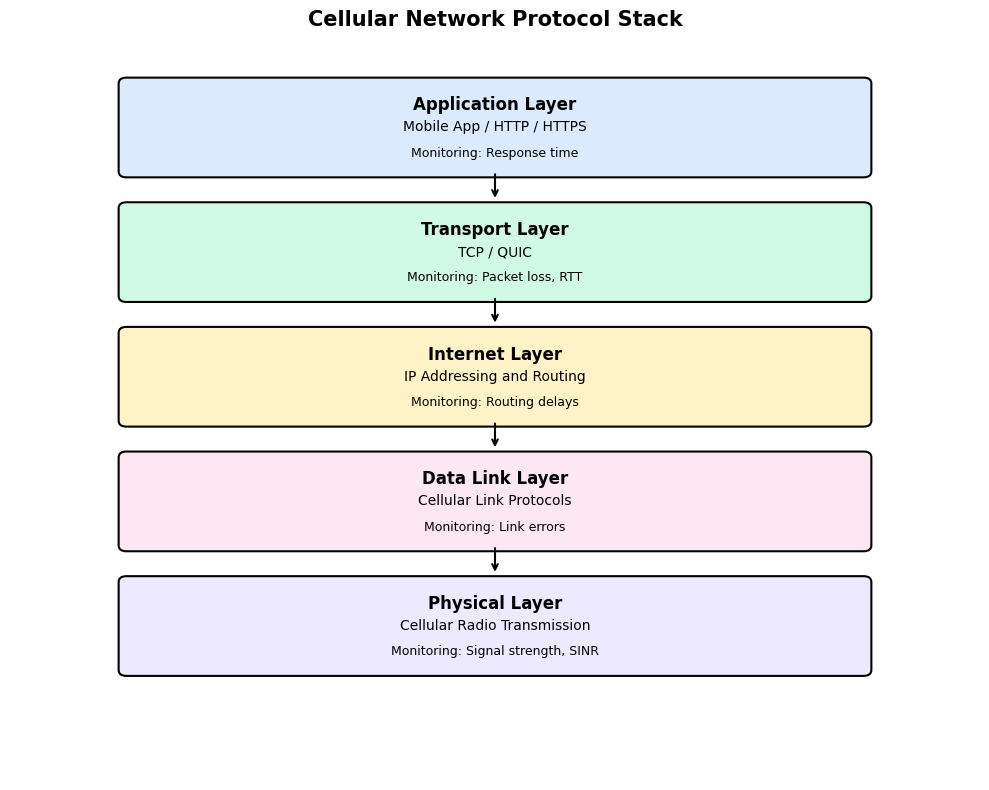

In [8]:
file_size_MB = 24
overhead_percent = 10
throughput_Mbps = 8

overhead_MB = file_size_MB * overhead_percent / 100
total_data_MB = file_size_MB + overhead_MB

total_data_Mb = total_data_MB * 8

transfer_time = total_data_Mb / throughput_Mbps

print("Original file size:", file_size_MB, "MB")
print("Additional overhead:", overhead_MB, "MB")
print("Total transmitted data:", total_data_MB, "MB")
print("Total transmitted data:", total_data_Mb, "megabits")
print("Minimum transfer time:", transfer_time, "seconds")


import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

layers = [
    ("Application Layer", "Mobile App / HTTP / HTTPS", "Monitoring: Response time"),
    ("Transport Layer", "TCP / QUIC", "Monitoring: Packet loss, RTT"),
    ("Internet Layer", "IP Addressing and Routing", "Monitoring: Routing delays"),
    ("Data Link Layer", "Cellular Link Protocols", "Monitoring: Link errors"),
    ("Physical Layer", "Cellular Radio Transmission", "Monitoring: Signal strength, SINR")
]

colors = ["#DCEAFE", "#D1FAE5", "#FEF3C7", "#FCE7F3", "#EDE9FE"]

for i, (title, protocol, monitoring) in enumerate(layers):
    y = 8.3 - i * 1.7

    box = FancyBboxPatch(
        (1.2, y), 7.6, 1.2,
        boxstyle="round,pad=0.08",
        facecolor=colors[i],
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        5, y + 0.9, title,
        ha="center", va="center",
        fontsize=12, fontweight="bold"
    )

    ax.text(
        5, y + 0.6, protocol,
        ha="center", va="center", fontsize=10
    )

    ax.text(
        5, y + 0.25, monitoring,
        ha="center", va="center", fontsize=9
    )

    if i < len(layers) - 1:
        ax.annotate(
            "", xy=(5, y - 0.4), xytext=(5, y),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title(
    "Cellular Network Protocol Stack",
    fontsize=15, fontweight="bold", pad=15
)

plt.tight_layout()
plt.show()


**Task 7 – Core Network Performance**

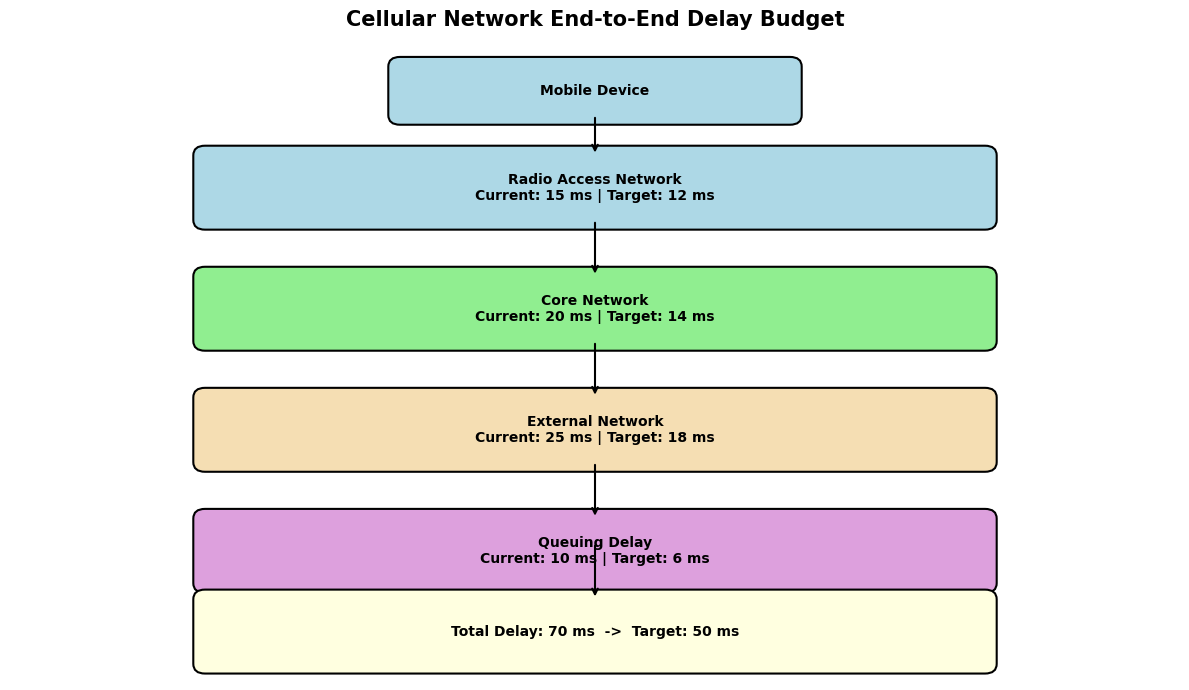

Current delay: 70 ms
Target delay: 50 ms
Required reduction: 20 ms


In [9]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

segments = [
    "Radio Access Network",
    "Core Network",
    "External Network",
    "Queuing Delay"
]

current = [15, 20, 25, 10]
target = [12, 14, 18, 6]

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def draw_box(x, y, w, h, text, color):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=10, fontweight="bold"
    )

draw_box(4, 7, 4, 0.6, "Mobile Device", "lightblue")

colors = ["lightblue", "lightgreen",
          "wheat", "plum"]

for i, segment in enumerate(segments):
    y = 5.7 - i * 1.5

    draw_box(
        2, y, 8, 0.8,
        f"{segment}\n"
        f"Current: {current[i]} ms | "
        f"Target: {target[i]} ms",
        colors[i]
    )

    if i == 0:
        ax.annotate(
            "", xy=(6, y + 0.8),
            xytext=(6, 7),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )
    else:
        ax.annotate(
            "", xy=(6, y + 0.8),
            xytext=(6, y + 1.5),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

draw_box(
    2, 0.2, 8, 0.8,
    "Total Delay: 70 ms  ->  Target: 50 ms",
    "lightyellow"
)

ax.annotate(
    "", xy=(6, 1.0), xytext=(6, 1.7),
    arrowprops=dict(arrowstyle="->", lw=1.5)
)

ax.set_title(
    "Cellular Network End-to-End Delay Budget",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Current delay:", sum(current), "ms")
print("Target delay:", sum(target), "ms")
print("Required reduction:",
      sum(current) - sum(target), "ms")


**Task 8 – Mobility and Handoff**

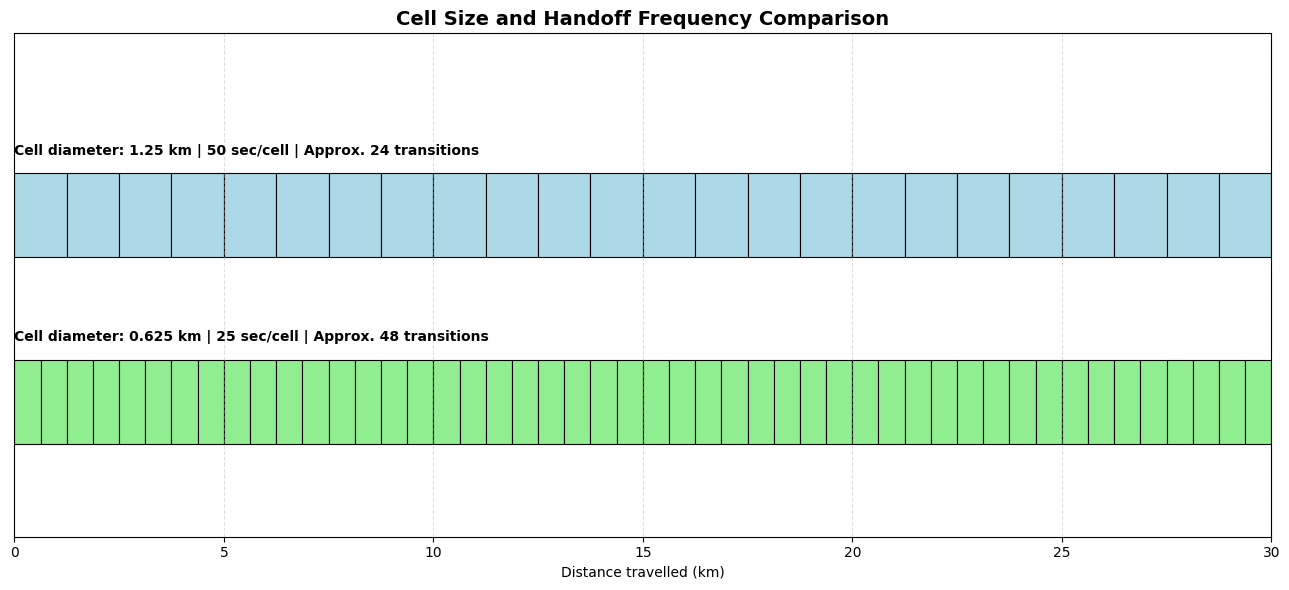

Journey distance: 30.0 km
For 1.25 km cells: approximately 24 transitions
For 0.625 km cells: approximately 48 transitions


In [10]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

speed_kmh = 90
journey_minutes = 20
cell_diameters = [1.25, 0.625]

distance = speed_kmh * journey_minutes / 60

fig, ax = plt.subplots(figsize=(13, 6))

colors = ["lightblue", "lightgreen"]
labels = ["Cell diameter: 1.25 km",
          "Cell diameter: 0.625 km"]

for row, diameter in enumerate(cell_diameters):
    y = 2 - row
    number_of_cells = round(distance / diameter)

    for i in range(number_of_cells):
        x = i * diameter

        cell = Rectangle(
            (x, y), diameter, 0.45,
            facecolor=colors[row],
            edgecolor="black",
            linewidth=0.8
        )
        ax.add_patch(cell)

    cell_time = diameter / speed_kmh * 3600
    transitions = distance / diameter

    ax.text(
        0, y + 0.55,
        f"{labels[row]} | "
        f"{cell_time:.0f} sec/cell | "
        f"Approx. {transitions:.0f} transitions",
        fontsize=10, fontweight="bold"
    )

ax.set_xlim(0, distance)
ax.set_ylim(0.5, 3.2)
ax.set_xlabel("Distance travelled (km)")
ax.set_yticks([])
ax.set_title(
    "Cell Size and Handoff Frequency Comparison",
    fontsize=14, fontweight="bold"
)
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("Journey distance:", distance, "km")
print("For 1.25 km cells: approximately 24 transitions")
print("For 0.625 km cells: approximately 48 transitions")


**Task 9 – PLMN and Roaming**

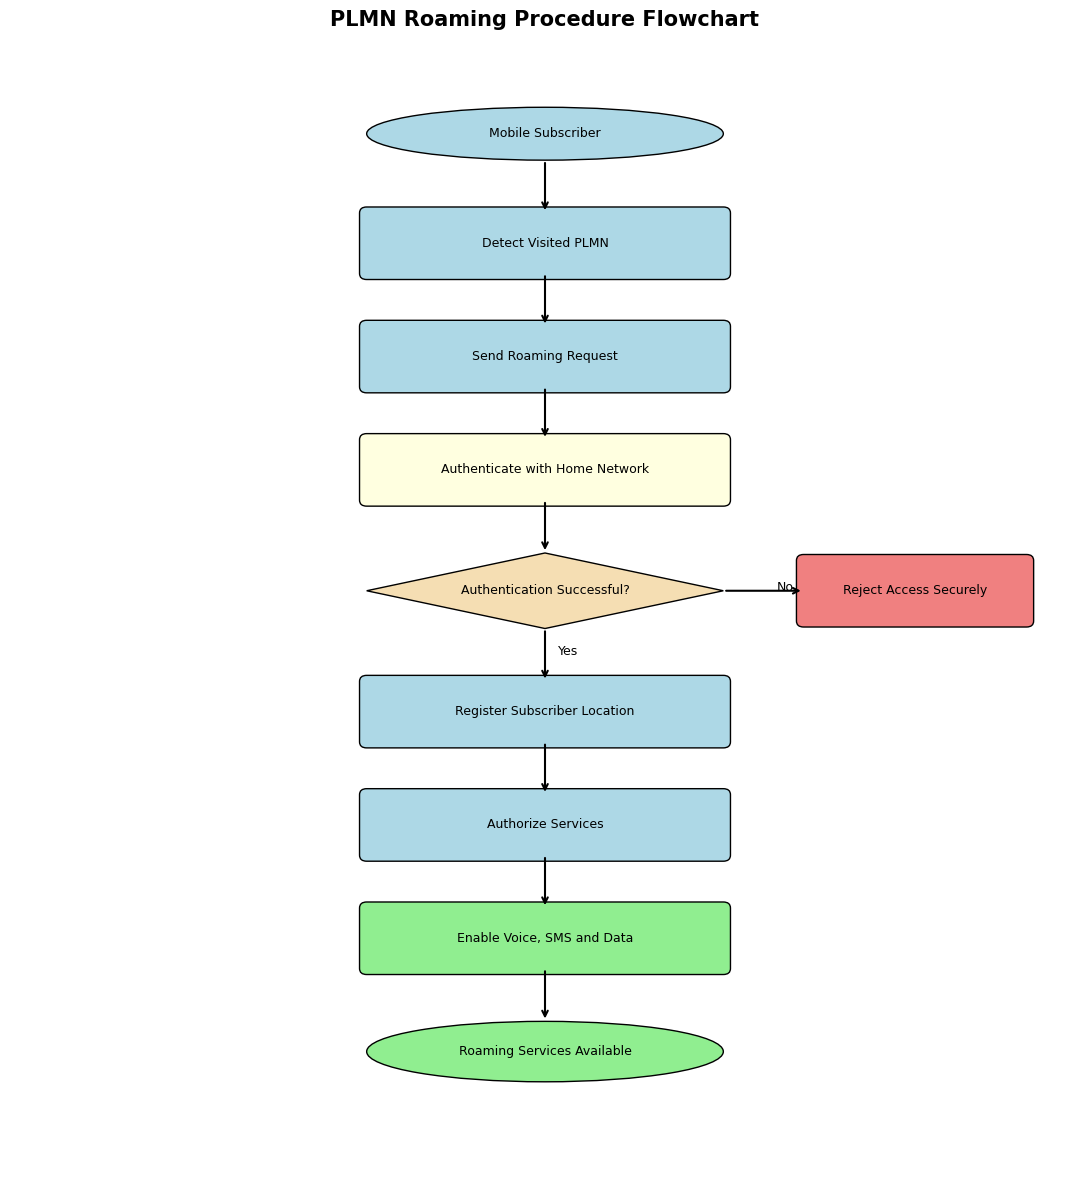

In [11]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

fig, ax = plt.subplots(figsize=(11, 12))
ax.set_xlim(0, 12)
ax.set_ylim(0, 15)
ax.axis("off")

def draw_box(x, y, w, h, text, color, shape="box"):
    if shape == "diamond":
        points = [
            (x + w/2, y + h),
            (x + w, y + h/2),
            (x + w/2, y),
            (x, y + h/2)
        ]
        patch = Polygon(
            points, closed=True,
            facecolor=color, edgecolor="black"
        )
    elif shape == "oval":
        patch = plt.matplotlib.patches.Ellipse(
            (x + w/2, y + h/2), w, h,
            facecolor=color, edgecolor="black"
        )
    else:
        patch = FancyBboxPatch(
            (x, y), w, h,
            boxstyle="round,pad=0.08",
            facecolor=color, edgecolor="black"
        )

    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, text,
            ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2, label=""):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )
    if label:
        ax.text((x1+x2)/2 + 0.15,
                (y1+y2)/2, label, fontsize=9)

draw_box(4, 13.5, 4, 0.7,
         "Mobile Subscriber", "lightblue", "oval")
draw_box(4, 12, 4, 0.8,
         "Detect Visited PLMN", "lightblue")
draw_box(4, 10.5, 4, 0.8,
         "Send Roaming Request", "lightblue")
draw_box(4, 9, 4, 0.8,
         "Authenticate with Home Network", "lightyellow")
draw_box(4, 7.3, 4, 1,
         "Authentication Successful?", "wheat", "diamond")

arrow(6, 13.5, 6, 12.8)
arrow(6, 12, 6, 11.3)
arrow(6, 10.5, 6, 9.8)
arrow(6, 9, 6, 8.3)
draw_box(4, 5.8, 4, 0.8,
         "Register Subscriber Location", "lightblue")
draw_box(4, 4.3, 4, 0.8,
         "Authorize Services", "lightblue")
draw_box(4, 2.8, 4, 0.8,
         "Enable Voice, SMS and Data", "lightgreen")
draw_box(4, 1.3, 4, 0.8,
         "Roaming Services Available", "lightgreen", "oval")

arrow(6, 7.3, 6, 6.6, "Yes")
arrow(6, 5.8, 6, 5.1)
arrow(6, 4.3, 6, 3.6)
arrow(6, 2.8, 6, 2.1)
draw_box(8.9, 7.4, 2.5, 0.8,
         "Reject Access Securely", "lightcoral")
arrow(8, 7.8, 8.9, 7.8, "No")

ax.set_title(
    "PLMN Roaming Procedure Flowchart",
    fontsize=15, fontweight="bold", pad=15
)

plt.tight_layout()
plt.show()


**Task 10 – Integrated Cellular Network Design**

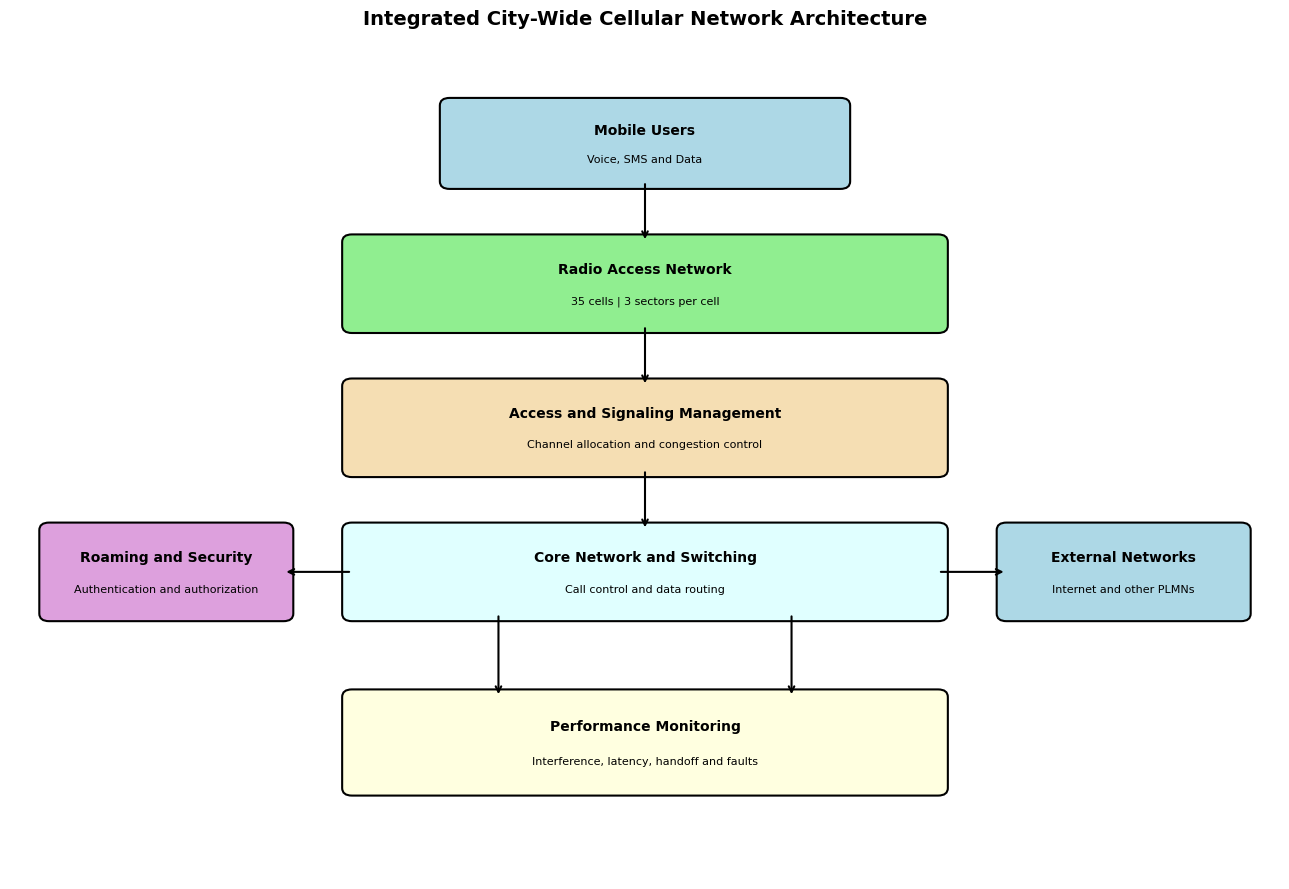

Channels per sector: 20
Users per sector: 500
Theoretical users per cell: 1500
Total theoretical capacity: 52500
Unavailable capacity: 7875
Effective city-wide capacity: 44625


In [12]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 13)
ax.set_ylim(0, 11)
ax.axis("off")

def draw_box(x, y, w, h, title, details, color):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.1",
        facecolor=color,
        edgecolor="black",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.68,
        title, ha="center", va="center",
        fontsize=10, fontweight="bold"
    )
    ax.text(
        x + w/2, y + h*0.30,
        details, ha="center", va="center",
        fontsize=8, wrap=True
    )

def arrow(x1, y1, x2, y2, label=""):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )
    if label:
        ax.text(
            (x1+x2)/2, (y1+y2)/2 + 0.15,
            label, ha="center", fontsize=8
        )

draw_box(4.5, 9.2, 4, 1,
         "Mobile Users",
         "Voice, SMS and Data",
         "lightblue")

draw_box(3.5, 7.3, 6, 1.1,
         "Radio Access Network",
         "35 cells | 3 sectors per cell",
         "lightgreen")

draw_box(3.5, 5.4, 6, 1.1,
         "Access and Signaling Management",
         "Channel allocation and congestion control",
         "wheat")

draw_box(3.5, 3.5, 6, 1.1,
         "Core Network and Switching",
         "Call control and data routing",
         "lightcyan")

draw_box(0.4, 3.5, 2.4, 1.1,
         "Roaming and Security",
         "Authentication and authorization",
         "plum")

draw_box(10.2, 3.5, 2.4, 1.1,
         "External Networks",
         "Internet and other PLMNs",
         "lightblue")

draw_box(3.5, 1.2, 6, 1.2,
         "Performance Monitoring",
         "Interference, latency, handoff and faults",
         "lightyellow")

arrow(6.5, 9.2, 6.5, 8.4)
arrow(6.5, 7.3, 6.5, 6.5)
arrow(6.5, 5.4, 6.5, 4.6)
arrow(3.5, 4.05, 2.8, 4.05)
arrow(9.5, 4.05, 10.2, 4.05)
arrow(5, 3.5, 5, 2.4)
arrow(8, 3.5, 8, 2.4)

ax.set_title(
    "Integrated City-Wide Cellular Network Architecture",
    fontsize=14, fontweight="bold", pad=15
)

plt.tight_layout()
plt.show()

cells = 35
channels_per_cell = 60
sectors_per_cell = 3
users_per_channel = 25
unavailable_percent = 15

channels_per_sector = channels_per_cell / sectors_per_cell

users_per_sector = channels_per_sector * users_per_channel
users_per_cell = users_per_sector * sectors_per_cell

theoretical_capacity = cells * users_per_cell

unavailable_capacity = (
    theoretical_capacity * unavailable_percent / 100
)
effective_capacity = theoretical_capacity - unavailable_capacity

print("Channels per sector:", int(channels_per_sector))
print("Users per sector:", int(users_per_sector))
print("Theoretical users per cell:", int(users_per_cell))
print("Total theoretical capacity:", int(theoretical_capacity))
print("Unavailable capacity:", int(unavailable_capacity))
print("Effective city-wide capacity:", int(effective_capacity))
